# Quickstart: a run with a known answer

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/clarkmit/abcd-biopsychosocial-prediction/blob/main/notebooks/01_quickstart.ipynb)

This notebook runs the pipeline end to end on a simulated panel in which the correct answer is known, then checks that the pipeline finds it. It shows how a run is configured, which stages it runs and where the results are.

It does not reproduce the article's findings, which need ABCD data that cannot be shared here (see [Data access and governance](../docs/data.md)). It takes a minute or two on a laptop CPU.

In [1]:
# Find the repository (or fetch it when running on Colab) and install the package.
import importlib, subprocess, sys
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "demo.yaml").exists()), None)
if ROOT is None:  # e.g. Google Colab
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/clarkmit/abcd-biopsychosocial-prediction"], check=True)
    ROOT = Path.cwd() / "abcd-biopsychosocial-prediction"
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", str(ROOT)], check=True)
    importlib.invalidate_caches()  # make the newly installed package importable in this session
print("repository:", ROOT.name)

repository: abcd-biopsychosocial-prediction


## Input: a simulated panel with a planted signal

`make_example_panel` resamples the fully simulated panel shipped in `data/simulated/` (every column drawn independently, so nothing is predictable) and plants one known structure at wave T2: a latent score drives three parent-report CBCL items and, together with `delta_not_liked_p`, the CBCL internalizing T-score `internal_D_p`. Every other column is noise. A correct run should therefore rank those four predictors first and explain a substantial share of the variance of `internal_D_p`, but not all of it, because noise was added.

In [2]:
from bpsp.simulation import PLANTED_FEATURES, make_example_panel

out_dir = ROOT / "outputs" / "quickstart"
out_dir.mkdir(parents=True, exist_ok=True)
panel_path = out_dir / "example_panel.csv"
panel = make_example_panel(ROOT / "data" / "simulated" / "CLEAN_ABCD_5_1_panel_simulated.csv", n_subjects=1000)
panel.to_csv(panel_path, index=False)

print(f"{panel['subject'].nunique()} simulated participants x {panel['time'].nunique()} waves, {panel.shape[1]} columns")
print("planted predictors:", ", ".join(PLANTED_FEATURES))

1000 simulated participants x 5 waves, 1609 columns
planted predictors: stubborn_p, disagreeable_p, blames_others_p, delta_not_liked_p


## Configuration

A run is described by one `PipelineConfig`. Every setting has the default of the published notebook and can be changed in Python or in a YAML file. `configs/demo.yaml` holds the settings used here, with smaller models than the published runs so that the run takes a minute or two.

In [3]:
from bpsp import Pipeline, PipelineConfig, configure_logging, ctx

cfg = PipelineConfig.from_yaml(ROOT / "configs" / "demo.yaml")
cfg.setup.DATA_PATH = str(panel_path)
cfg.output_dir = str(out_dir)

print("target:", cfg.main.target_options, "| wave: T" + cfg.main.tp_option, "| split:", cfg.main.split)
print("model sizes:", cfg.model_overrides)

target: internal_D_p | wave: T2 | split: across_categories
model sizes: {'catboost': {'iterations': 100}, 'xgboost': {'n_estimators': 100}, 'random_forest': {'n_estimators': 100}}


## Run

`setup` loads the panel, builds the variable registry and applies the per-target circularity exclusions. `main` splits the data (70/30), fits CatBoost, XGBoost and random forest base learners and a linear meta-learner on their out-of-fold predictions, pairwise products and mean, and computes the consensus feature importance. Stage logs are long, so this notebook shows warnings only (`configure_logging("INFO")` shows everything).

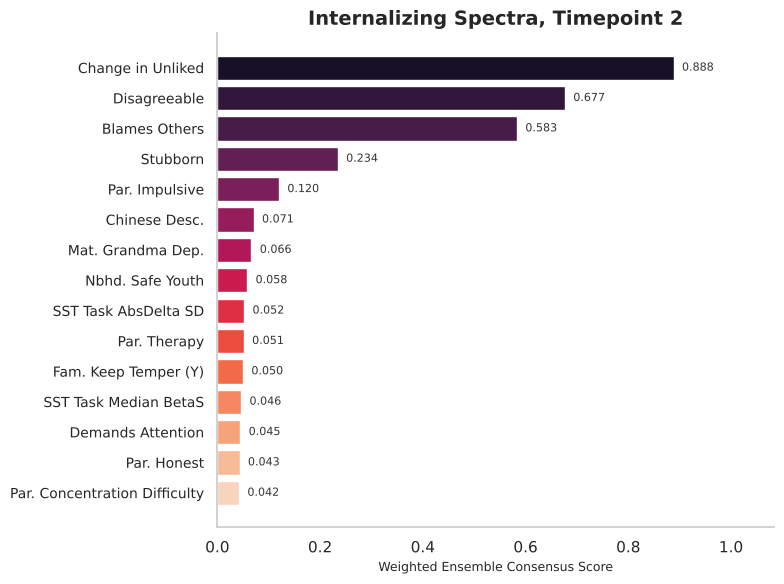

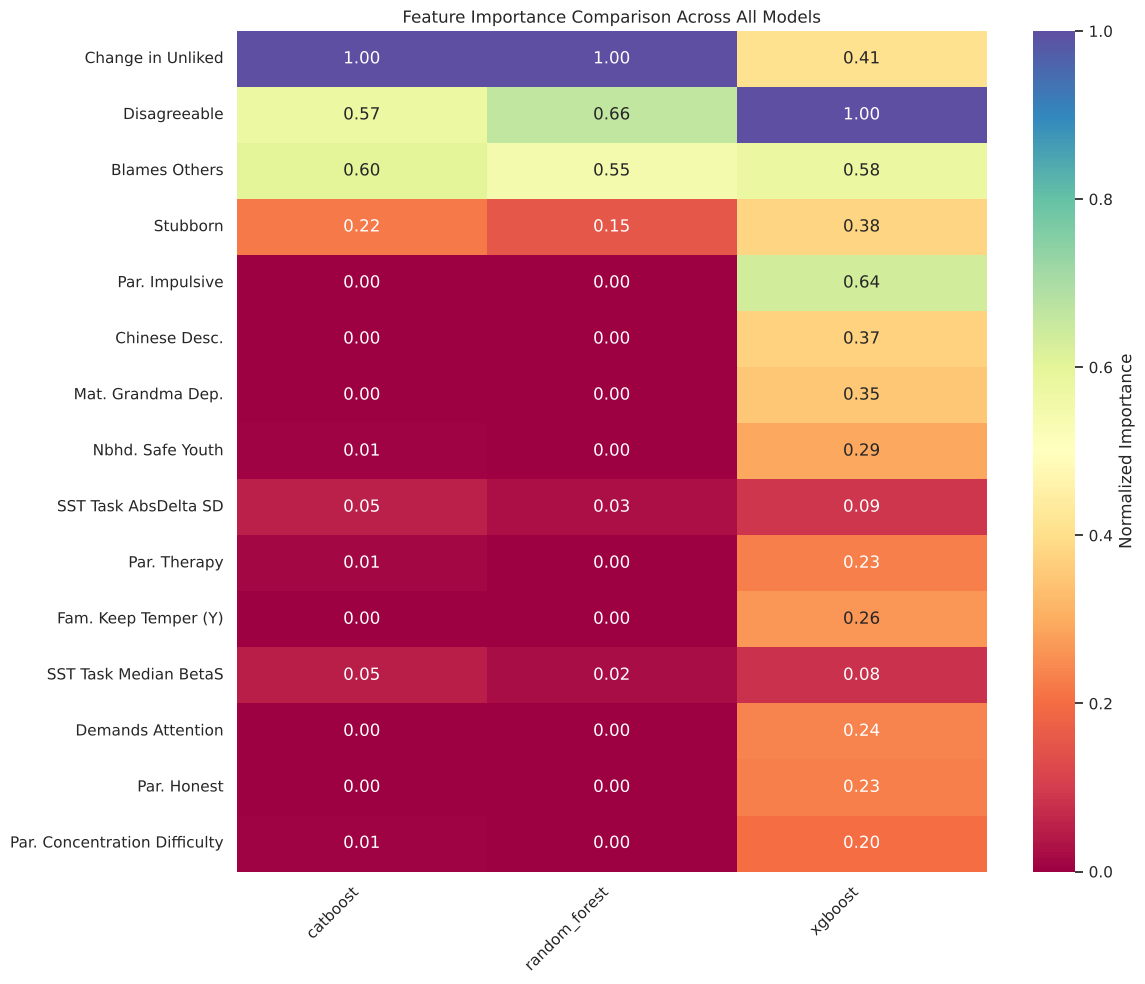

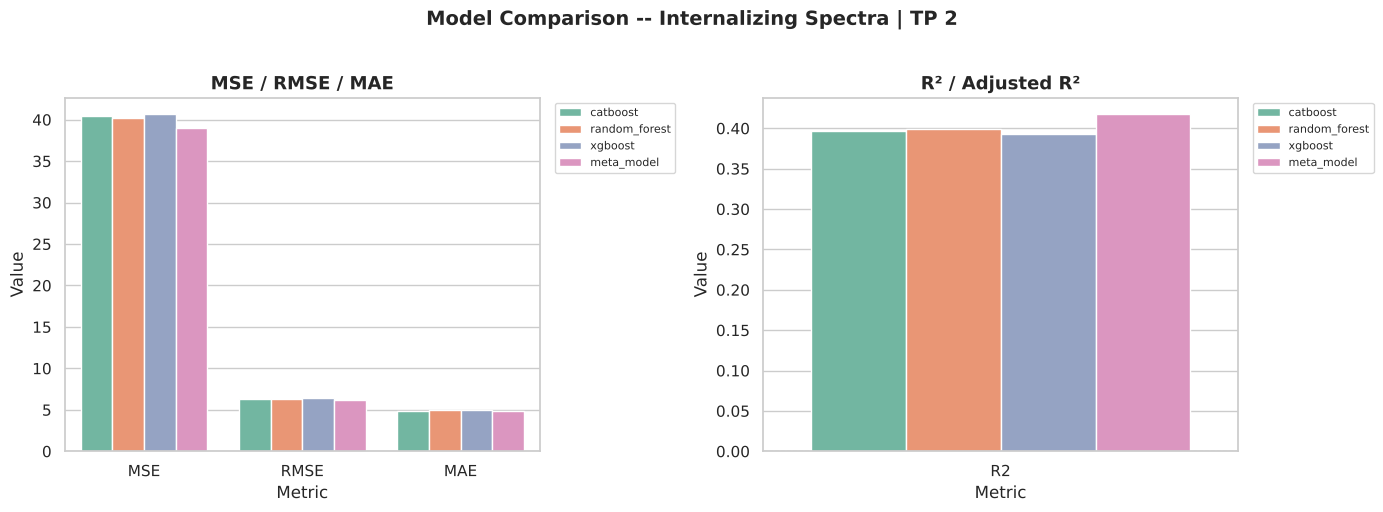

,mse,rmse,mae,r2,adj_r2
catboost,40.405668,6.356545,4.897921,0.396185,NaN
random_forest,40.176945,6.338529,4.922695,0.399603,NaN
xgboost,40.630783,6.374228,4.962448,0.392821,NaN
meta_model,39.000101,6.245006,4.840948,0.417190,NaN


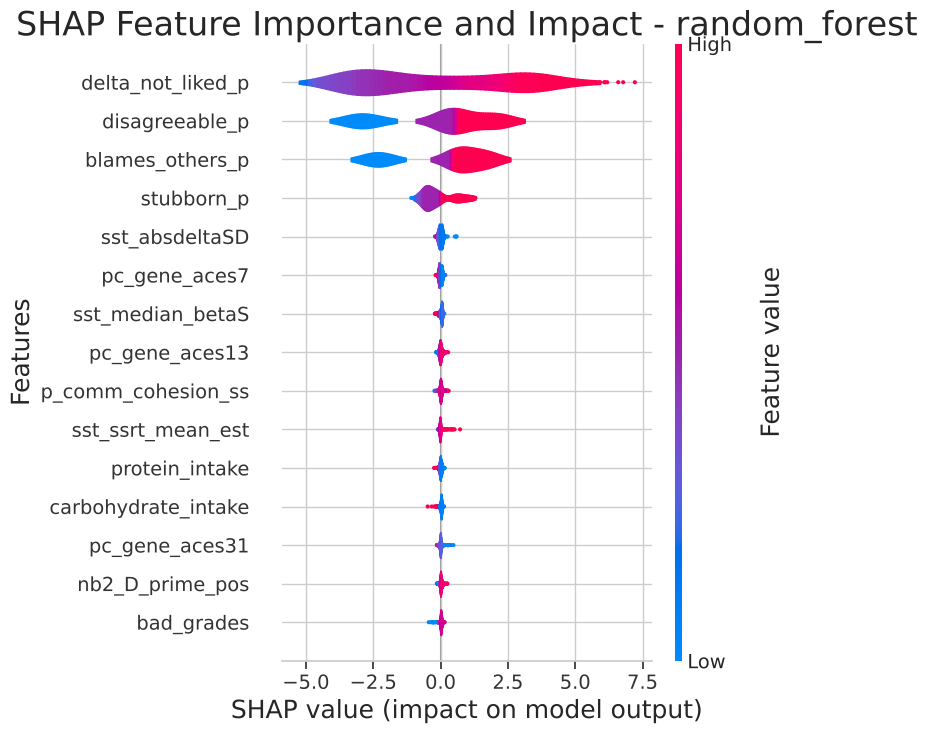

main: 58 s


In [4]:
configure_logging("WARNING")
pipe = Pipeline(cfg)
pipe.run(["main"])
print(f"main: {pipe.timings['main']:.0f} s")

## Results

Held-out performance of each base learner and of the stacked ensemble (`meta_model`) on the 30% test split:

In [5]:
import pandas as pd

metrics = pd.DataFrame(ctx.metrics_dict_full["metrics"][0]).T[["r2", "rmse", "mae"]]
metrics.round(3)

,r2,rmse,mae
catboost,0.396,6.357,4.898
random_forest,0.400,6.339,4.923
xgboost,0.393,6.374,4.962
meta_model,0.417,6.245,4.841


Weighted consensus feature importance is each base learner's feature importance, normalized to its largest value, multiplied by that learner's contribution to the meta-learner and summed across learners. The planted predictors should take the top four ranks:

In [6]:
planted = {ctx.DISPLAY_NAMES.get(name, name) for name in PLANTED_FEATURES}
top = ctx.consensus_df["weighted_score"].sort_values(ascending=False).head(8).to_frame()
top["planted"] = top.index.isin(planted)
top.round(3)

,weighted_score,planted
Change in Unliked,0.888,True
Disagreeable,0.677,True
Blames Others,0.583,True
Stubborn,0.234,True
Par. Impulsive,0.120,False
Chinese Desc.,0.071,False
Mat. Grandma Dep.,0.066,False
Nbhd. Safe Youth,0.058,False


In [7]:
recovered = set(top.index[:4]) == planted
print("all four planted predictors ranked first:", recovered)

all four planted predictors ranked first: True


## A validation stage

Validation stages reuse the fitted pipeline. `base_learners` compares each base learner with the stacked ensemble on the held-out data:

Target,TP,Split,Metric,Models,Mean CatBoost,Mean XGBoost,Mean Random Forest,Mean ensemble,Ensemble ≥ best base (%),Ensemble within 0.005 or better (%),Median gain,Most often best base
internal_D_p,2,across_categories,R²,1,0.396,0.393,0.400,0.417,100,100,0.018,Random Forest


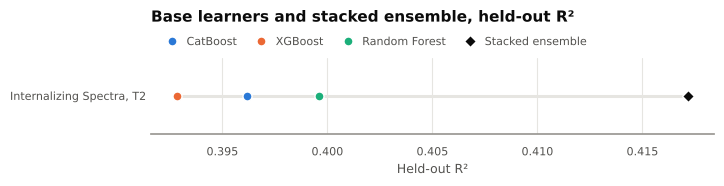

In [8]:
pipe.run_stage("base_learners")

## Limitations

The panel is simulated with one planted effect, so the run checks the mechanics and the recovery of a known signal, not the scientific findings. The models are smaller than in the published analyses, and TabPFN is not used because across-category runs leave it out.

All tables and figures of this run are in `outputs/quickstart/`. For every stage, see [`02_full_analysis.ipynb`](02_full_analysis.ipynb) and the [stage list](../docs/stages.md).